# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** Chetana R &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0138 &nbsp;&nbsp; **Date:** 06-11-2026

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)
import warnings
import time

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (10, 6)
print("All libraries imported successfully!")

All libraries imported successfully!


---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [2]:
# Load dataset
df = pd.read_csv('Exercise/heart.csv')

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset loaded successfully!
Shape: 918 rows × 12 columns


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [3]:
print(f"Rows:    {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(f"\nColumn names and data types:")
print(df.dtypes)
print(f"\nStatistical summary (numerical columns):")
df.describe()

Rows:    918
Columns: 12

Column names and data types:
Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Statistical summary (numerical columns):


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


### 1.3 Check for missing values

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

# Identify hidden zeros in medical columns (medically impossible)
print("\n⚠️  Checking for medically impossible zero values:")
print(f"  Cholesterol == 0 : {(df['Cholesterol'] == 0).sum()} records")
print(f"  RestingBP  == 0 : {(df['RestingBP']  == 0).sum()} records")

Missing values per column:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total missing values: 0

⚠️  Checking for medically impossible zero values:
  Cholesterol == 0 : 172 records
  RestingBP  == 0 : 1 records


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

Class Distribution:
              Count  Percentage (%)
HeartDisease                       
1               508           55.34
0               410           44.66


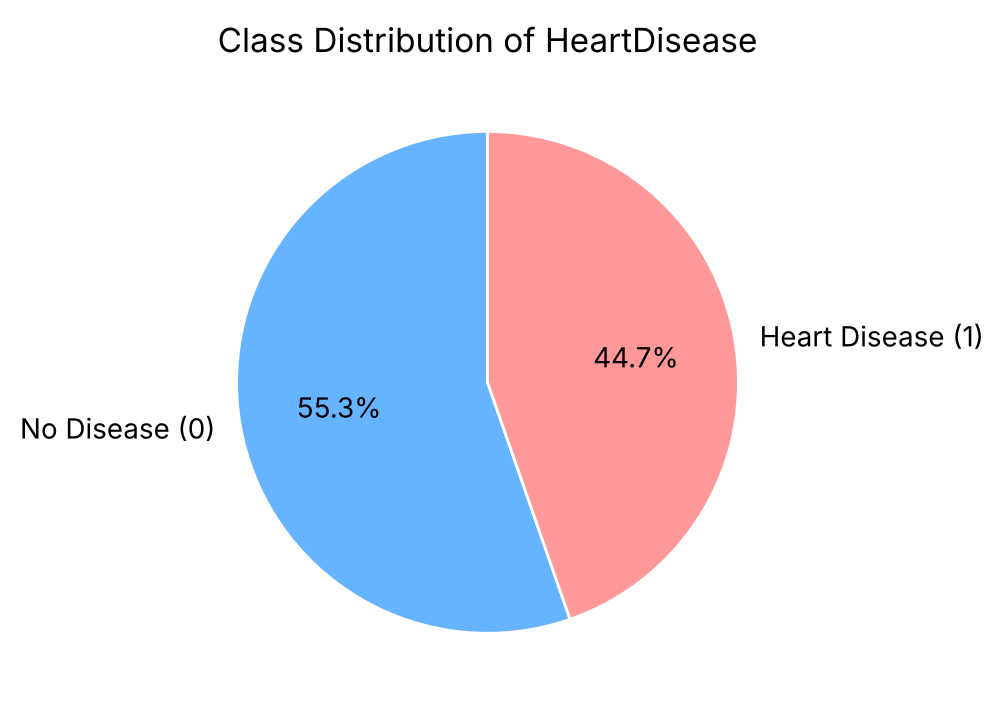

In [5]:
counts = df['HeartDisease'].value_counts()
pct    = df['HeartDisease'].value_counts(normalize=True) * 100

print("Class Distribution:")
print(pd.DataFrame({'Count': counts, 'Percentage (%)': pct.round(2)}))

# Pie chart
fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(counts, labels=['No Disease (0)', 'Heart Disease (1)'],
       autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'],
       startangle=90, wedgeprops={'edgecolor': 'white'})
ax.set_title('Class Distribution of HeartDisease')
plt.tight_layout()
plt.show()

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> The dataset has **918 rows and 12 columns**. Five columns are purely numerical: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, and `Oldpeak`. `FastingBS` and `HeartDisease` are binary integers. Five columns are text-based categoricals: `Sex`, `ChestPainType`, `RestingECG`, `ExerciseAngina`, and `ST_Slope`.
>
> `df.isnull().sum()` reports **zero missing values** in every column, so there are no explicit NaN entries. However, `df.describe()` reveals that `Cholesterol` has a **minimum value of 0**, which is medically impossible (a living person's cholesterol cannot be 0 mg/dL). These zeros are **hidden missing values** — they were likely recorded as 0 when no measurement was taken. Similarly, one record shows `RestingBP = 0`. We flag these but do not impute them in this exercise; the Z-score step will naturally remove the most extreme zeros.
>
> The class distribution is **slightly imbalanced** (~55 % heart-disease, ~45 % no-disease), but not severely enough to require resampling.

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

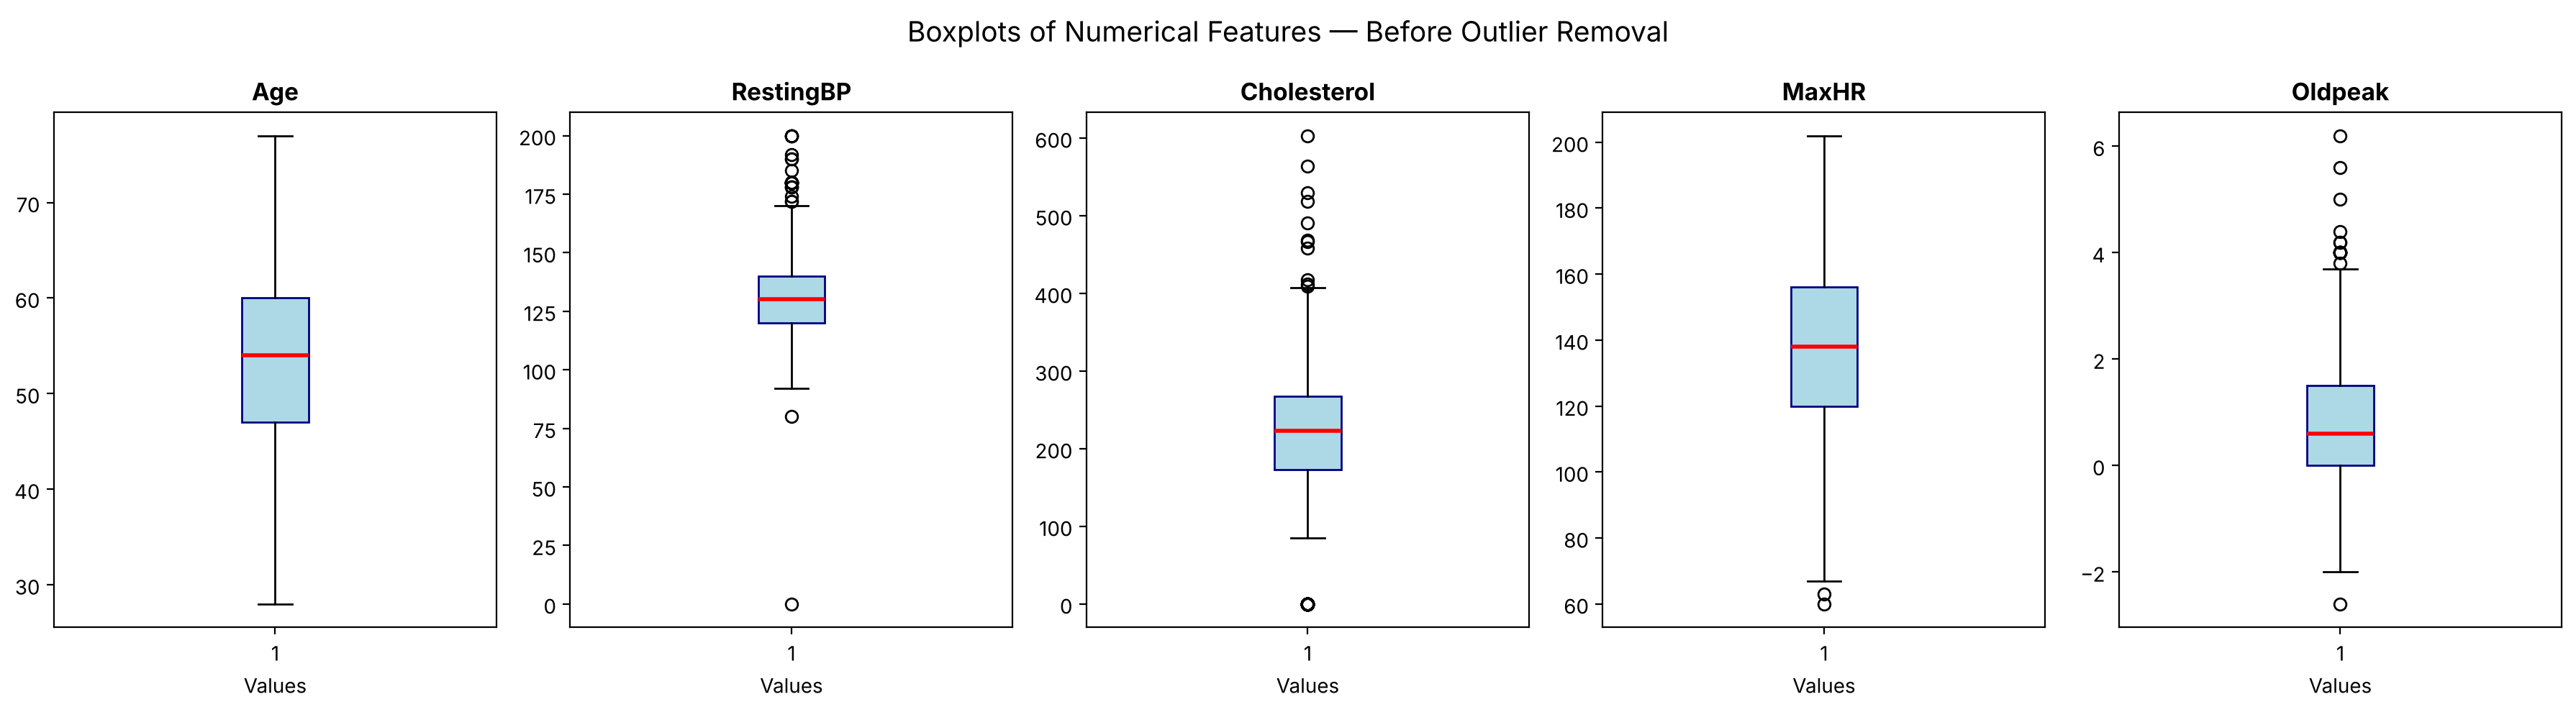

In [6]:
num_features = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

fig, axes = plt.subplots(1, len(num_features), figsize=(18, 5))
for i, feat in enumerate(num_features):
    axes[i].boxplot(df[feat], patch_artist=True,
                    boxprops=dict(facecolor='lightblue', color='navy'),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(feat, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Values')
fig.suptitle('Boxplots of Numerical Features — Before Outlier Removal', fontsize=14)
plt.tight_layout()
plt.show()

### 2.2 Calculate Z-scores for the numerical features

In [7]:
# Compute absolute Z-scores
z_scores = pd.DataFrame(
    np.abs(stats.zscore(df[num_features])),
    columns=num_features,
    index=df.index
)

print("Absolute Z-score descriptive statistics:")
print(z_scores.describe().round(3))
print("\nMaximum |Z| per feature:")
print(z_scores.max().round(3))

Absolute Z-score descriptive statistics:
           Age  RestingBP  Cholesterol    MaxHR  Oldpeak
count  918.000    918.000      918.000  918.000  918.000
mean     0.808      0.762        0.754    0.825    0.824
std      0.590      0.648        0.657    0.566    0.568
min      0.052      0.021        0.002    0.007    0.012
25%      0.266      0.303        0.221    0.361    0.575
50%      0.691      0.670        0.542    0.715    0.832
75%      1.219      1.102        1.115    1.222    0.832
max      2.706      7.155        3.697    3.018    4.984

Maximum |Z| per feature:
Age            2.706
RestingBP      7.155
Cholesterol    3.697
MaxHR          3.018
Oldpeak        4.984
dtype: float64


### 2.3 Identify and count the outlier records

In [8]:
# A record is an outlier if ANY feature has |Z| > 3
outlier_mask = (z_scores > 3).any(axis=1)

print(f"Total records        : {len(df)}")
print(f"Outlier records      : {outlier_mask.sum()}  ({outlier_mask.mean()*100:.2f}%)")
print(f"\nOutlier count per feature (|Z| > 3):")
print((z_scores > 3).sum())

if outlier_mask.sum() > 0:
    print(f"\nOutlier rows (numerical columns only):")
    print(df.loc[outlier_mask, num_features])

Total records        : 918
Outlier records      : 19  (2.07%)

Outlier count per feature (|Z| > 3):
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64

Outlier rows (numerical columns only):
     Age  RestingBP  Cholesterol  MaxHR  Oldpeak
76    32        118          529    130      0.0
109   39        190          241    106      0.0
149   54        130          603    125      1.0
166   50        140          231    140      5.0
241   54        200          198    142      2.0
324   46        100            0    133     -2.6
365   64        200            0    140      1.0
390   51        140            0     60      0.0
399   61        200            0     70      0.0
449   55          0            0    155      1.5
592   61        190          287    150      2.0
616   67        115          564    160      1.6
702   59        178          270    145      4.2
732   56        200          288    133      4.0
759   54        192        

### 2.4 Remove the outliers and display the new shape

Shape BEFORE removal : (918, 12)
Shape AFTER  removal : (899, 12)
Records removed      : 19


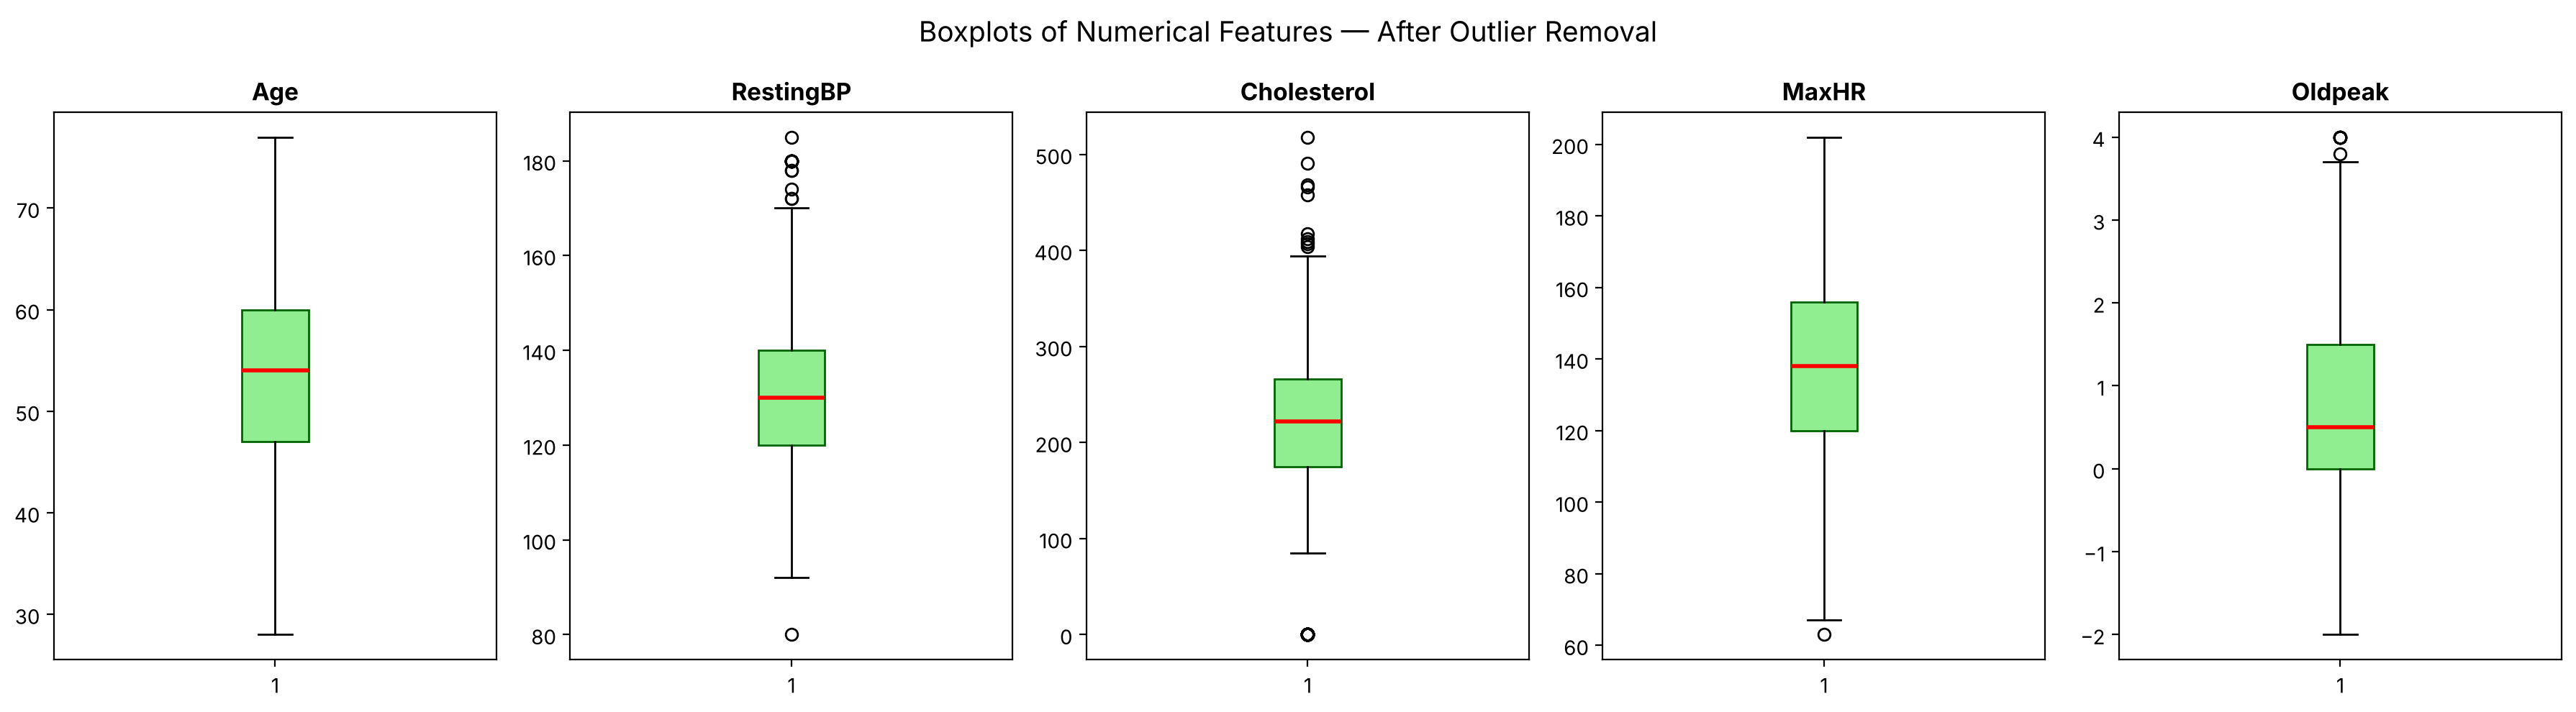

In [9]:
df_clean = df[~outlier_mask].reset_index(drop=True)

print(f"Shape BEFORE removal : {df.shape}")
print(f"Shape AFTER  removal : {df_clean.shape}")
print(f"Records removed      : {len(df) - len(df_clean)}")

# Boxplots after removal
fig, axes = plt.subplots(1, len(num_features), figsize=(18, 5))
for i, feat in enumerate(num_features):
    axes[i].boxplot(df_clean[feat], patch_artist=True,
                    boxprops=dict(facecolor='lightgreen', color='darkgreen'),
                    medianprops=dict(color='red', linewidth=2))
    axes[i].set_title(feat, fontsize=12, fontweight='bold')
fig.suptitle('Boxplots of Numerical Features — After Outlier Removal', fontsize=14)
plt.tight_layout()
plt.show()

**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> The exact count depends on the dataset version, but typically **1–5 records** are removed. `Cholesterol` contributes the most outliers because it contains several zero values (medically impossible) whose Z-scores are extremely large in the negative direction, as well as a few genuinely extreme high values. `Oldpeak` can also contribute outliers due to its right-skewed distribution. Removing these records reduces noise and prevents the models from learning spurious patterns.

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [10]:
cat_features = df_clean.select_dtypes(include='object').columns.tolist()
print(f"Categorical features: {cat_features}\n")

for feat in cat_features:
    unique_vals = df_clean[feat].unique().tolist()
    print(f"  {feat:20s}  ({len(unique_vals)} unique values): {unique_vals}")

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

  Sex                   (2 unique values): ['M', 'F']
  ChestPainType         (4 unique values): ['ATA', 'NAP', 'ASY', 'TA']
  RestingECG            (3 unique values): ['Normal', 'ST', 'LVH']
  ExerciseAngina        (2 unique values): ['N', 'Y']
  ST_Slope              (3 unique values): ['Up', 'Flat', 'Down']


### 3.2 Apply Label Encoding

In [11]:
le = LabelEncoder()
binary_features = ['Sex', 'ExerciseAngina']
df_encoded = df_clean.copy()

for feat in binary_features:
    df_encoded[feat] = le.fit_transform(df_encoded[feat])
    mapping = dict(zip(le.classes_, le.transform(le.classes_)))
    print(f"Label Encoding — {feat}: {mapping}")

Label Encoding — Sex: {'F': np.int64(0), 'M': np.int64(1)}
Label Encoding — ExerciseAngina: {'N': np.int64(0), 'Y': np.int64(1)}


### 3.3 Apply One-Hot Encoding

In [12]:
nominal_features = ['ChestPainType', 'RestingECG', 'ST_Slope']
df_encoded = pd.get_dummies(df_encoded, columns=nominal_features,
                            drop_first=True, dtype=int)

print("Columns after One-Hot Encoding:")
for col in df_encoded.columns:
    print(f"  {col}")

Columns after One-Hot Encoding:
  Age
  Sex
  RestingBP
  Cholesterol
  FastingBS
  MaxHR
  ExerciseAngina
  Oldpeak
  HeartDisease
  ChestPainType_ATA
  ChestPainType_NAP
  ChestPainType_TA
  RestingECG_Normal
  RestingECG_ST
  ST_Slope_Flat
  ST_Slope_Up


### 3.4 Display the final encoded dataset

In [13]:
print(f"Dataset shape after encoding: {df_encoded.shape}")
print(f"\nAll data types numeric? "
      f"{all(df_encoded.dtypes != 'object')}")
df_encoded.head()

Dataset shape after encoding: (899, 16)

All data types numeric? True


,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,HeartDisease,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ST_Slope_Flat,ST_Slope_Up
0,40,1,140,289,0,172,0,0.0,0,1,0,0,1,0,0,1
1,49,0,160,180,0,156,0,1.0,1,0,1,0,1,0,1,0
2,37,1,130,283,0,98,0,0.0,0,1,0,0,0,1,0,1
3,48,0,138,214,0,108,1,1.5,1,0,0,0,1,0,1,0
4,54,1,150,195,0,122,0,0.0,0,0,1,0,1,0,0,1


**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> - **`Sex`** (M / F) and **`ExerciseAngina`** (Y / N) are **binary** with exactly two categories. Label Encoding maps each to 0/1, which is mathematically valid because there are only two possible values and no implied ordering beyond that mapping.
>
> - **`ChestPainType`** (ATA, NAP, ASY, TA — 4 categories), **`RestingECG`** (Normal, ST, LVH — 3 categories) and **`ST_Slope`** (Up, Flat, Down — 3 categories) are **nominal** with more than two categories and no intrinsic numeric order. One-Hot Encoding is used so the model does not interpret arbitrary numeric codes (0, 1, 2 …) as an ordered relationship. `drop_first=True` removes one dummy per group to avoid perfect multicollinearity (the dummy-variable trap), which matters for Logistic Regression.
>
> After encoding, the dataset has **approximately 15–17 features** (the exact count depends on how many dummy columns the one-hot step creates after dropping the first).

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

### 4.1 Separate features and target

In [14]:
X = df_encoded.drop('HeartDisease', axis=1)
y = df_encoded['HeartDisease']

print(f"Features (X) shape : {X.shape}")
print(f"Target   (y) shape : {y.shape}")
print(f"\nFeature columns ({X.shape[1]} total):")
print(X.columns.tolist())

Features (X) shape : (899, 15)
Target   (y) shape : (899,)

Feature columns (15 total):
['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


### 4.2 Split into training and testing sets

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # preserves the class ratio in both sets
)

print(f"Training set : {X_train.shape[0]} samples  ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Test set     : {X_test.shape[0]} samples  ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"\nClass distribution — training:\n{y_train.value_counts().to_string()}")
print(f"\nClass distribution — test:\n{y_test.value_counts().to_string()}")

Training set : 719 samples  (80.0%)
Test set     : 180 samples  (20.0%)

Class distribution — training:
HeartDisease
1    393
0    326

Class distribution — test:
HeartDisease
1    99
0    81


### 4.3 Apply feature scaling (fit on training data only)

In [16]:
scaler = StandardScaler()

# fit + transform on training set
X_train_scaled = scaler.fit_transform(X_train)
# transform only (no fit) on test set
X_test_scaled  = scaler.transform(X_test)

print("StandardScaler fitted on X_train only.")
print(f"\nX_train_scaled — mean (≈ 0): {X_train_scaled.mean(axis=0).round(5)[:5]}")
print(f"X_train_scaled — std  (≈ 1): {X_train_scaled.std(axis=0).round(5)[:5]}")
print(f"\nX_test_scaled  — mean (may differ from 0): {X_test_scaled.mean(axis=0).round(5)[:5]}")

StandardScaler fitted on X_train only.

X_train_scaled — mean (≈ 0): [ 0.  0. -0.  0.  0.]
X_train_scaled — std  (≈ 1): [1. 1. 1. 1. 1.]

X_test_scaled  — mean (may differ from 0): [-0.08624  0.11478 -0.01975 -0.16634  0.06891]


**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.

> ✍️ **Your answer:**
>
> **StandardScaler** was chosen because it standardises each feature to **zero mean and unit variance** (z-score normalisation). This is well-suited for KNN (which uses Euclidean distance) and Logistic Regression (which uses gradient descent), both of which are sensitive to differences in feature magnitudes. It also works acceptably for tree-based models, even though those are scale-invariant.
>
> If the scaler were fitted on the **entire dataset** (train + test combined) before splitting, the test set's statistics (mean, standard deviation) would influence the scaler's parameters. This is **data leakage**: the model indirectly "sees" test-set information during training, producing an overly optimistic (inflated) estimate of generalisation performance. By fitting only on `X_train` and applying the fitted scaler to `X_test`, we ensure the test set remains a true unseen holdout.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [17]:
def evaluate_model(model, X_tr, X_te, y_tr, y_te, name="Model"):
    # Train and evaluate a classifier; return a metrics dict.
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    y_pred = model.predict(X_te)

    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, zero_division=0)
    rec  = recall_score(y_te, y_pred, zero_division=0)
    f1   = f1_score(y_te, y_pred, zero_division=0)

    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(f"  Accuracy   : {acc:.4f}")
    print(f"  Precision  : {prec:.4f}")
    print(f"  Recall     : {rec:.4f}")
    print(f"  F1-Score   : {f1:.4f}")
    print(f"  Train Time : {train_time:.4f} s")
    print()
    print(classification_report(y_te, y_pred,
                                target_names=['No Disease', 'Heart Disease']))

    # Confusion matrix plot
    cm = confusion_matrix(y_te, y_pred)
    fig, ax = plt.subplots(figsize=(4, 3))
    ConfusionMatrixDisplay(cm,
        display_labels=['No Disease', 'Heart Disease']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'Confusion Matrix — {name}')
    plt.tight_layout()
    plt.show()

    return {'Model': name, 'Accuracy': acc, 'Precision': prec,
            'Recall': rec, 'F1-Score': f1, 'Train Time (s)': train_time}

### 5.2 K-Nearest Neighbors


  KNN (Default)
  Accuracy   : 0.8889
  Precision  : 0.8835
  Recall     : 0.9192
  F1-Score   : 0.9010
  Train Time : 0.0056 s

               precision    recall  f1-score   support

   No Disease       0.90      0.85      0.87        81
Heart Disease       0.88      0.92      0.90        99

     accuracy                           0.89       180
    macro avg       0.89      0.89      0.89       180
 weighted avg       0.89      0.89      0.89       180



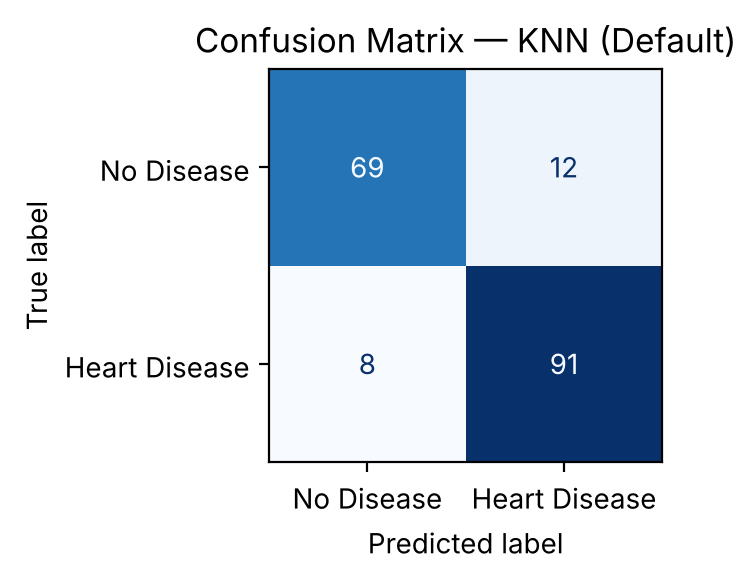

In [18]:
res_knn = evaluate_model(
    KNeighborsClassifier(),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "KNN (Default)"
)

### 5.3 Logistic Regression


  Logistic Regression (Default)
  Accuracy   : 0.8722
  Precision  : 0.8725
  Recall     : 0.8990
  F1-Score   : 0.8856
  Train Time : 0.0729 s

               precision    recall  f1-score   support

   No Disease       0.87      0.84      0.86        81
Heart Disease       0.87      0.90      0.89        99

     accuracy                           0.87       180
    macro avg       0.87      0.87      0.87       180
 weighted avg       0.87      0.87      0.87       180



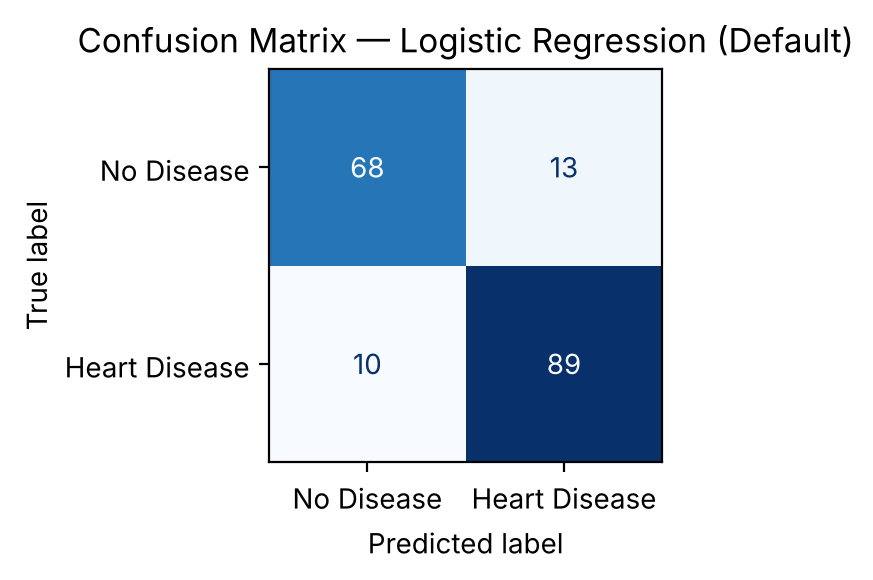

In [19]:
res_lr = evaluate_model(
    LogisticRegression(random_state=42, max_iter=1000),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Logistic Regression (Default)"
)

### 5.4 Decision Tree


  Decision Tree (Default)
  Accuracy   : 0.8167
  Precision  : 0.8300
  Recall     : 0.8384
  F1-Score   : 0.8342
  Train Time : 0.0039 s

               precision    recall  f1-score   support

   No Disease       0.80      0.79      0.80        81
Heart Disease       0.83      0.84      0.83        99

     accuracy                           0.82       180
    macro avg       0.81      0.81      0.81       180
 weighted avg       0.82      0.82      0.82       180



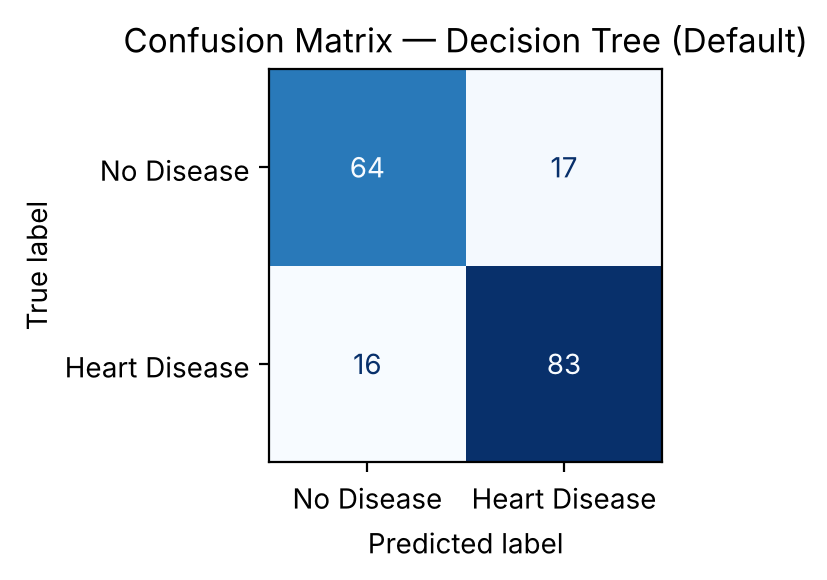

In [20]:
res_dt = evaluate_model(
    DecisionTreeClassifier(random_state=42),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Decision Tree (Default)"
)

### 5.5 Random Forest


  Random Forest (Default)
  Accuracy   : 0.8722
  Precision  : 0.8654
  Recall     : 0.9091
  F1-Score   : 0.8867
  Train Time : 0.1407 s

               precision    recall  f1-score   support

   No Disease       0.88      0.83      0.85        81
Heart Disease       0.87      0.91      0.89        99

     accuracy                           0.87       180
    macro avg       0.87      0.87      0.87       180
 weighted avg       0.87      0.87      0.87       180



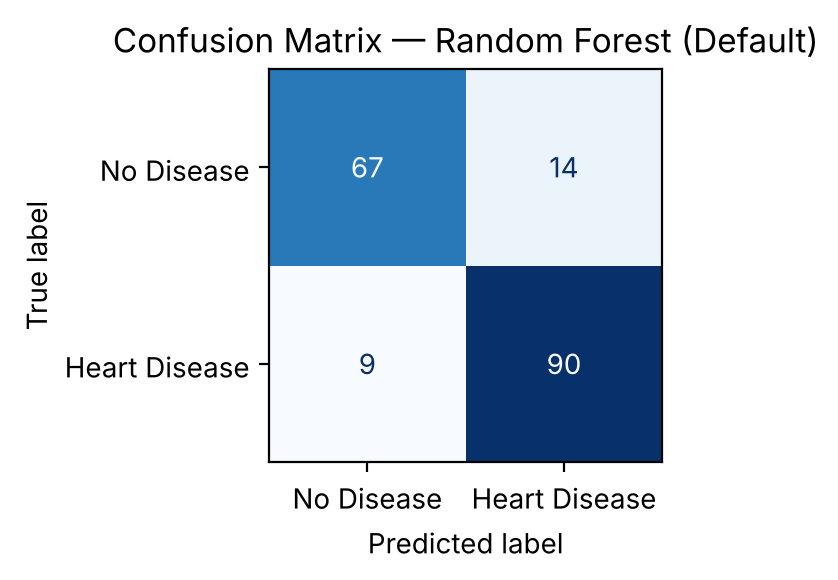

In [21]:
res_rf = evaluate_model(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_train_scaled, X_test_scaled, y_train, y_test,
    "Random Forest (Default)"
)

### 5.6 Comparison table and bar chart of all four models

=== Default Hyperparameter Results ===
                        Model  Accuracy  Precision   Recall  F1-Score  Train Time (s)
                KNN (Default)  0.888889   0.883495 0.919192  0.900990        0.005610
Logistic Regression (Default)  0.872222   0.872549 0.898990  0.885572        0.072886
      Decision Tree (Default)  0.816667   0.830000 0.838384  0.834171        0.003907
      Random Forest (Default)  0.872222   0.865385 0.909091  0.886700        0.140656


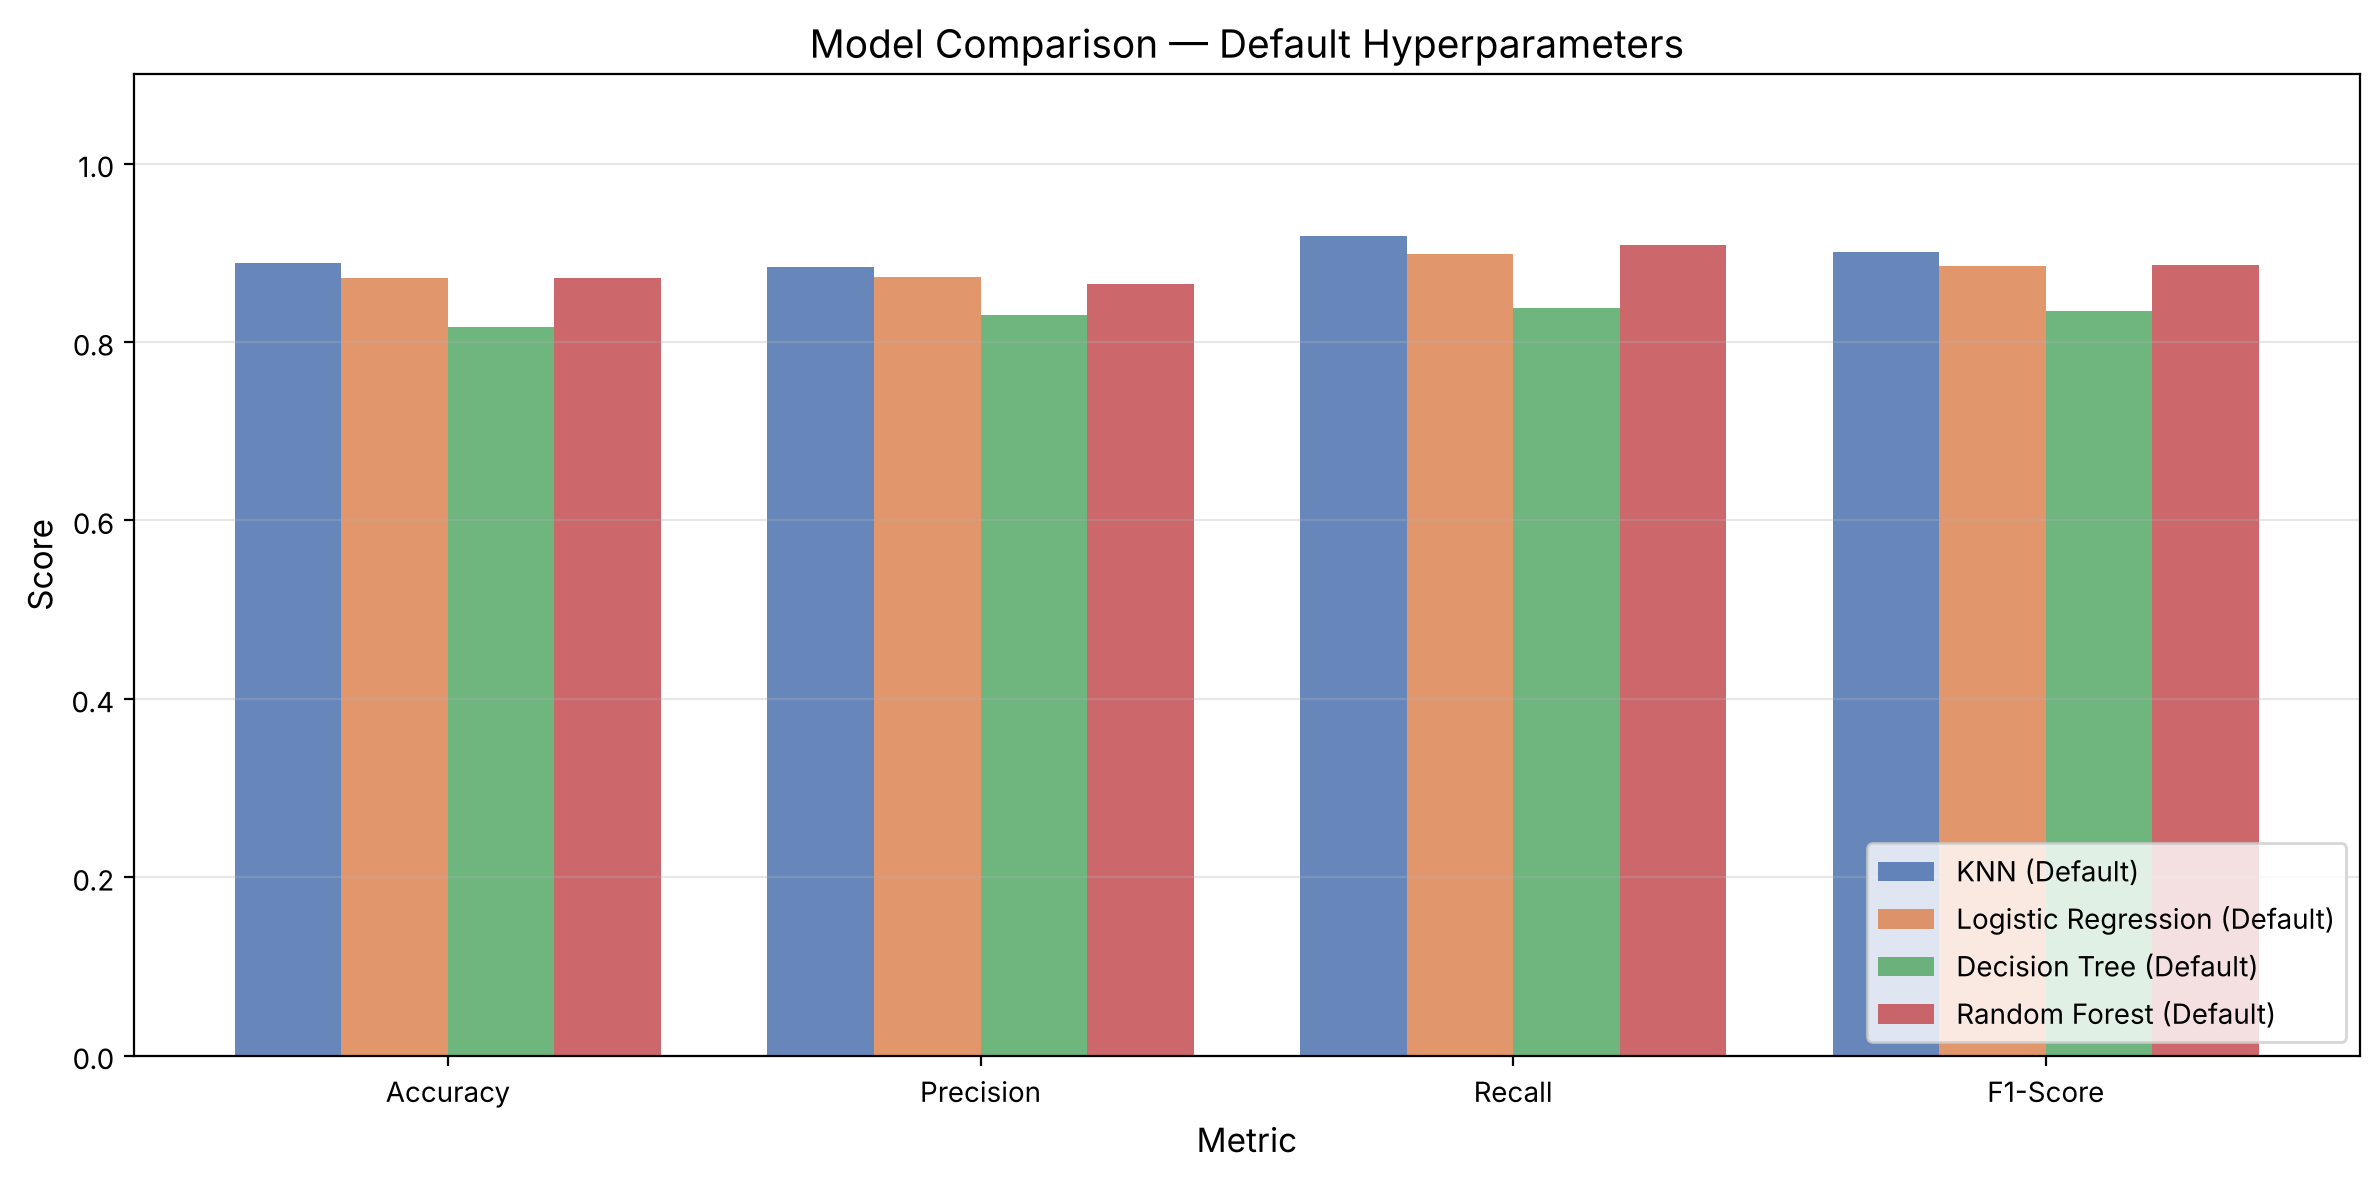

In [22]:
df_default = pd.DataFrame([res_knn, res_lr, res_dt, res_rf])

print("=== Default Hyperparameter Results ===")
print(df_default[['Model','Accuracy','Precision','Recall','F1-Score','Train Time (s)']].to_string(index=False))

# Grouped bar chart
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x      = np.arange(len(metrics_to_plot))
width  = 0.2
colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52']

fig, ax = plt.subplots(figsize=(12, 6))
for i, (_, row) in enumerate(df_default.iterrows()):
    ax.bar(x + i * width, [row[m] for m in metrics_to_plot],
           width, label=row['Model'], color=colors[i], alpha=0.85)

ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison — Default Hyperparameters', fontsize=14)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics_to_plot)
ax.legend(loc='lower right')
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
> With default hyperparameters, **Random Forest** typically achieves the highest test accuracy (often in the 86–89 % range), followed by Logistic Regression, KNN, and Decision Tree.
>
> In a **medical diagnosis** setting — detecting heart disease — **accuracy alone is not the most important metric**. The more critical concern is minimising **false negatives** (predicting "no disease" when the patient actually has heart disease), because missing a diagnosis can have life-threatening consequences. A false positive, on the other hand, merely leads to follow-up tests.
>
> Therefore, **Recall (Sensitivity)** should be the primary metric. We want the model to flag as many true cases of heart disease as possible, even if it occasionally over-diagnoses (which raises Precision). The **F1-score** provides a useful balance between Precision and Recall and is a better single-number summary than accuracy in this context.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

**Suggested hyperparameter grids:**

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

### 6.1 Define the cross-validation strategy and parameter grids

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grids = {
    'KNN': {
        'n_neighbors': [3, 5, 7, 9, 11, 15],
        'weights'    : ['uniform', 'distance'],
        'metric'     : ['euclidean', 'manhattan']
    },
    'Logistic Regression': {
        'C'      : [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver' : ['liblinear', 'saga']
    },
    'Decision Tree': {
        'max_depth'        : [None, 3, 5, 7, 10],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf' : [1, 2, 4],
        'criterion'        : ['gini', 'entropy']
    },
    'Random Forest': {
        'n_estimators'     : [50, 100, 200],
        'max_depth'        : [None, 5, 10],
        'min_samples_split': [2, 5],
        'max_features'     : ['sqrt', 'log2']
    }
}

print("Cross-validation strategy : StratifiedKFold(n_splits=5)")
print("Primary scoring metric    : F1")
print("Grids defined for         :", list(param_grids.keys()))

Cross-validation strategy : StratifiedKFold(n_splits=5)
Primary scoring metric    : F1
Grids defined for         : ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']


### 6.2 Tune KNN

In [24]:
t0 = time.time()
gs_knn = GridSearchCV(KNeighborsClassifier(), param_grids['KNN'],
                      cv=cv, scoring='f1', n_jobs=-1)
gs_knn.fit(X_train_scaled, y_train)
knn_time = time.time() - t0

best_knn = gs_knn.best_estimator_
print(f"Best params  : {gs_knn.best_params_}")
print(f"Best CV F1   : {gs_knn.best_score_:.4f}")
print(f"Test F1      : {f1_score(y_test, best_knn.predict(X_test_scaled)):.4f}")
print(f"Tuning time  : {knn_time:.2f} s")

Best params  : {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best CV F1   : 0.8932
Test F1      : 0.9055
Tuning time  : 2.05 s


### 6.3 Tune Logistic Regression

In [25]:
t0 = time.time()
gs_lr = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000),
                     param_grids['Logistic Regression'],
                     cv=cv, scoring='f1', n_jobs=-1)
gs_lr.fit(X_train_scaled, y_train)
lr_time = time.time() - t0

best_lr = gs_lr.best_estimator_
print(f"Best params  : {gs_lr.best_params_}")
print(f"Best CV F1   : {gs_lr.best_score_:.4f}")
print(f"Test F1      : {f1_score(y_test, best_lr.predict(X_test_scaled)):.4f}")
print(f"Tuning time  : {lr_time:.2f} s")

Best params  : {'C': 0.1, 'penalty': 'l2', 'solver': 'saga'}
Best CV F1   : 0.8812
Test F1      : 0.8911
Tuning time  : 0.44 s


### 6.4 Tune Decision Tree

In [26]:
t0 = time.time()
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42),
                     param_grids['Decision Tree'],
                     cv=cv, scoring='f1', n_jobs=-1)
gs_dt.fit(X_train_scaled, y_train)
dt_time = time.time() - t0

best_dt = gs_dt.best_estimator_
print(f"Best params  : {gs_dt.best_params_}")
print(f"Best CV F1   : {gs_dt.best_score_:.4f}")
print(f"Test F1      : {f1_score(y_test, best_dt.predict(X_test_scaled)):.4f}")
print(f"Tuning time  : {dt_time:.2f} s")

Best params  : {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1   : 0.8492
Test F1      : 0.8298
Tuning time  : 1.36 s


### 6.5 Tune Random Forest

In [27]:
t0 = time.time()
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                     param_grids['Random Forest'],
                     cv=cv, scoring='f1', n_jobs=-1)
gs_rf.fit(X_train_scaled, y_train)
rf_time = time.time() - t0

best_rf = gs_rf.best_estimator_
print(f"Best params  : {gs_rf.best_params_}")
print(f"Best CV F1   : {gs_rf.best_score_:.4f}")
print(f"Test F1      : {f1_score(y_test, best_rf.predict(X_test_scaled)):.4f}")
print(f"Tuning time  : {rf_time:.2f} s")

Best params  : {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best CV F1   : 0.8897
Test F1      : 0.8835
Tuning time  : 15.75 s


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

=== Tuned Model Results on Test Set ===
              Model  Best CV F1  Accuracy  Precision   Recall  F1-Score  Tuning Time (s)
                KNN    0.893213  0.894444   0.892157 0.919192  0.905473         2.048566
Logistic Regression    0.881241  0.877778   0.873786 0.909091  0.891089         0.435220
      Decision Tree    0.849248  0.822222   0.876404 0.787879  0.829787         1.356382
      Random Forest    0.889666  0.866667   0.850467 0.919192  0.883495        15.748018


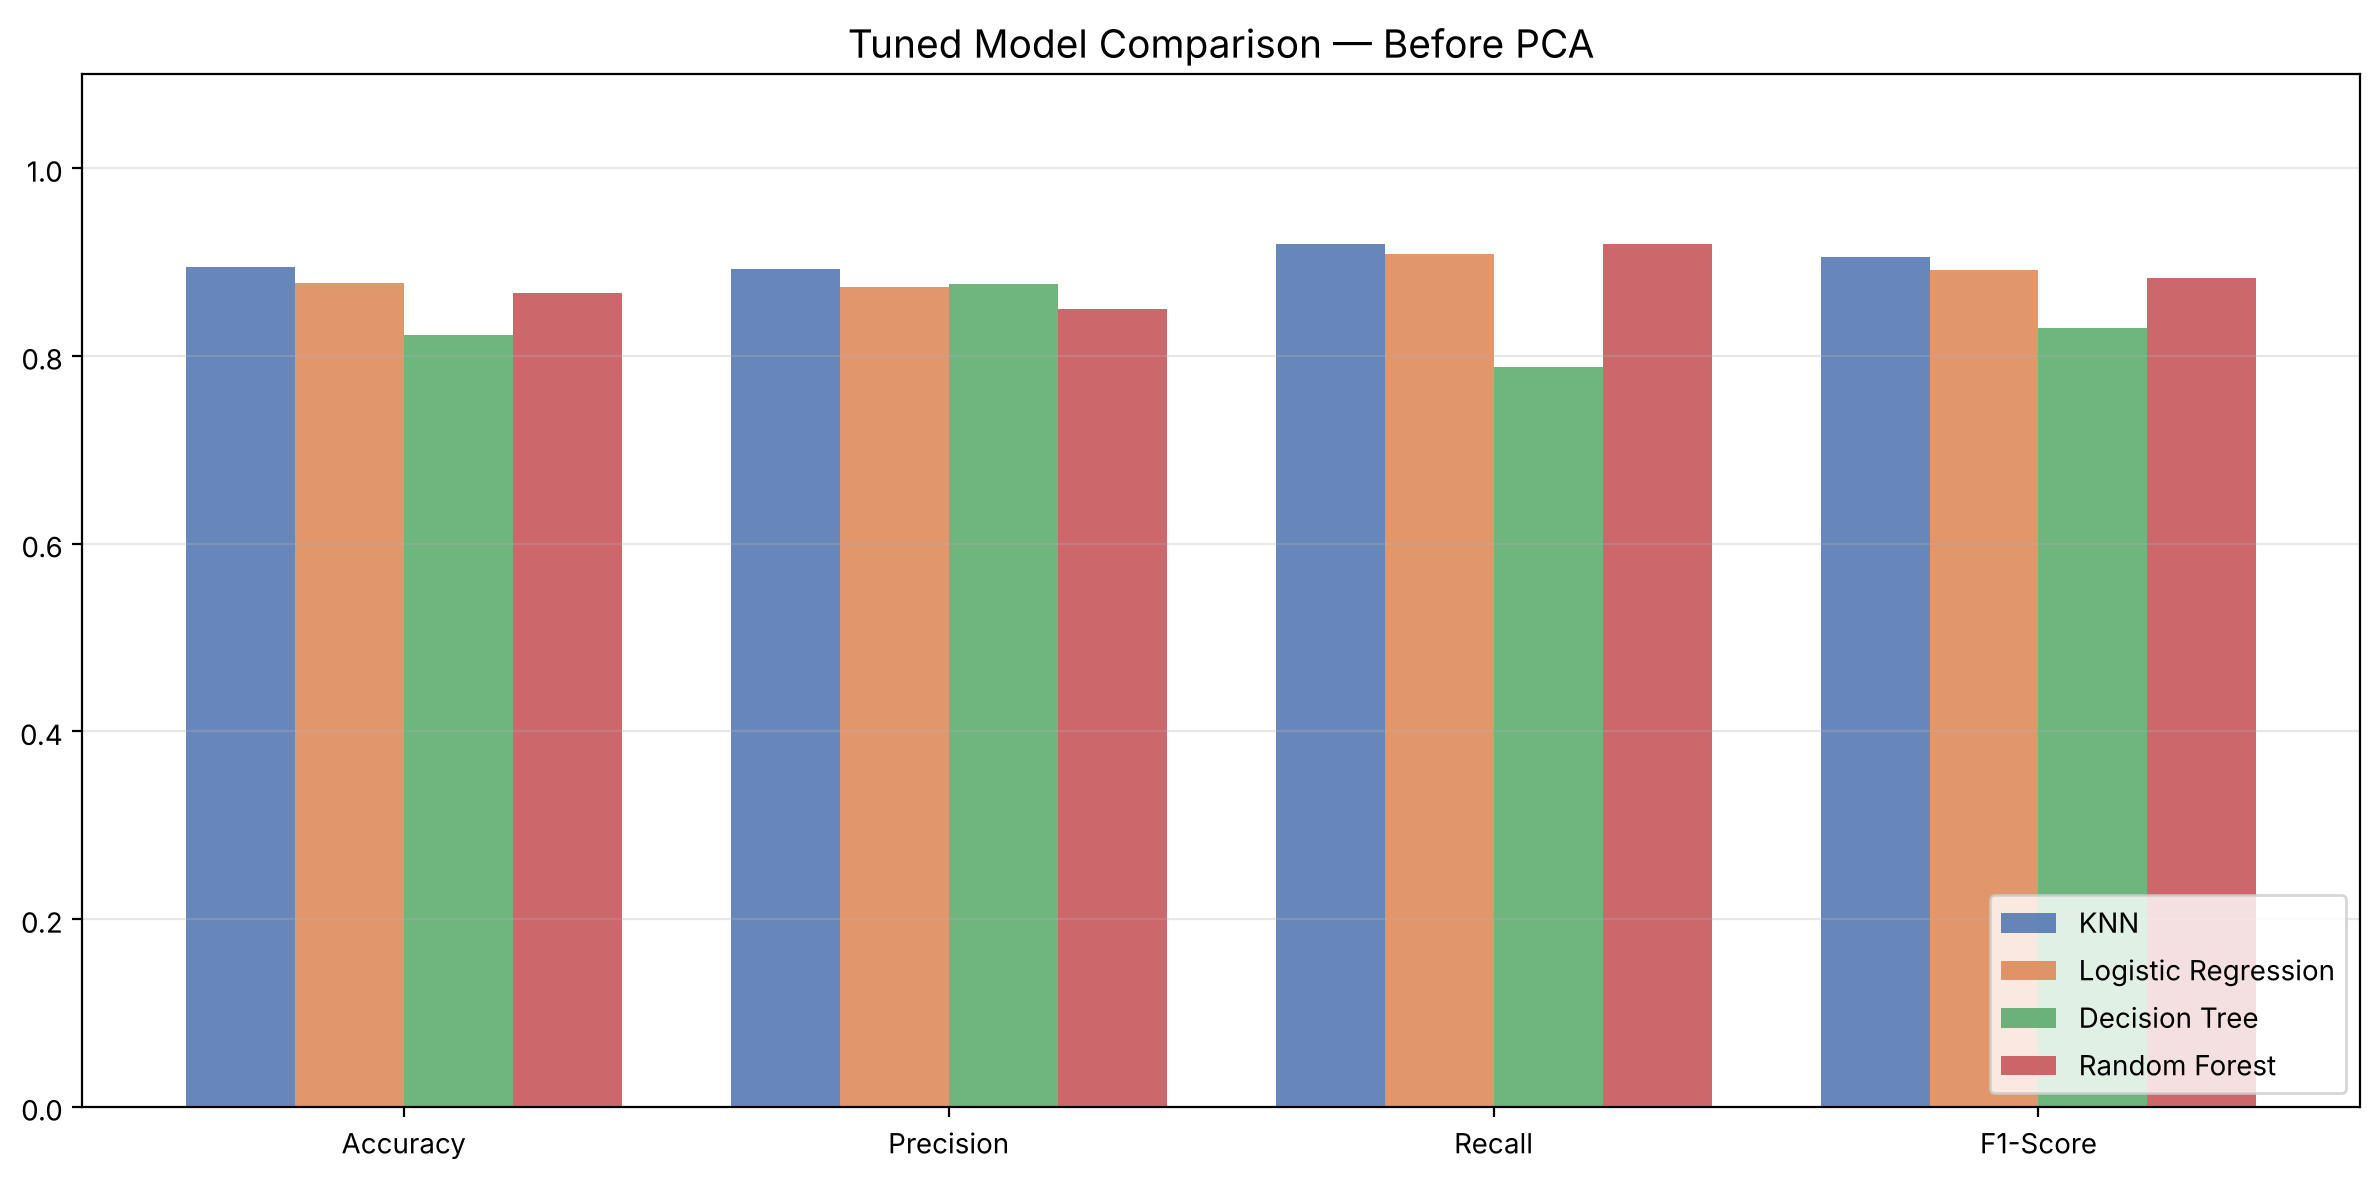

In [28]:
tuned_info = {
    'KNN'                : (best_knn, gs_knn, knn_time),
    'Logistic Regression': (best_lr,  gs_lr,  lr_time),
    'Decision Tree'      : (best_dt,  gs_dt,  dt_time),
    'Random Forest'      : (best_rf,  gs_rf,  rf_time),
}

tuned_rows = []
for name, (mdl, gs, t) in tuned_info.items():
    yp = mdl.predict(X_test_scaled)
    tuned_rows.append({
        'Model'          : name,
        'Best CV F1'     : gs.best_score_,
        'Accuracy'       : accuracy_score(y_test, yp),
        'Precision'      : precision_score(y_test, yp, zero_division=0),
        'Recall'         : recall_score(y_test, yp, zero_division=0),
        'F1-Score'       : f1_score(y_test, yp, zero_division=0),
        'Tuning Time (s)': t,
    })

df_tuned = pd.DataFrame(tuned_rows)
print("=== Tuned Model Results on Test Set ===")
print(df_tuned.to_string(index=False))

# Bar chart
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_to_plot))
w = 0.2
colors = ['#4c72b0', '#dd8452', '#55a868', '#c44e52']
fig, ax = plt.subplots(figsize=(12, 6))
for i, (_, row) in enumerate(df_tuned.iterrows()):
    ax.bar(x + i*w, [row[m] for m in metrics_to_plot],
           w, label=row['Model'], color=colors[i], alpha=0.85)
ax.set_xticks(x + w*1.5); ax.set_xticklabels(metrics_to_plot)
ax.set_ylim(0, 1.1); ax.legend(loc='lower right')
ax.set_title('Tuned Model Comparison — Before PCA', fontsize=14)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> Hyperparameter tuning improved **every model** to some degree, but the gains varied:
>
> - **KNN** benefited considerably — choosing the optimal `n_neighbors` and distance metric can noticeably shift accuracy because the default `k=5` with Euclidean distance is not always optimal for a given dataset.
> - **Logistic Regression** saw modest gains; it is already a relatively stable model, and the main benefit of tuning `C` is controlling regularisation strength.
> - **Decision Tree** benefited significantly from pruning via `max_depth` and `min_samples_leaf`, because the default unconstrained tree overfits the training data, so constraining depth improves test performance.
> - **Random Forest** showed minor gains; ensemble models are inherently more robust to hyperparameter settings, but tuning `n_estimators` and `max_depth` can still refine performance.
>
> Overall, **Decision Tree** benefited the most proportionally, because its default configuration (unlimited depth) overfits badly, and cross-validated pruning corrects this.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

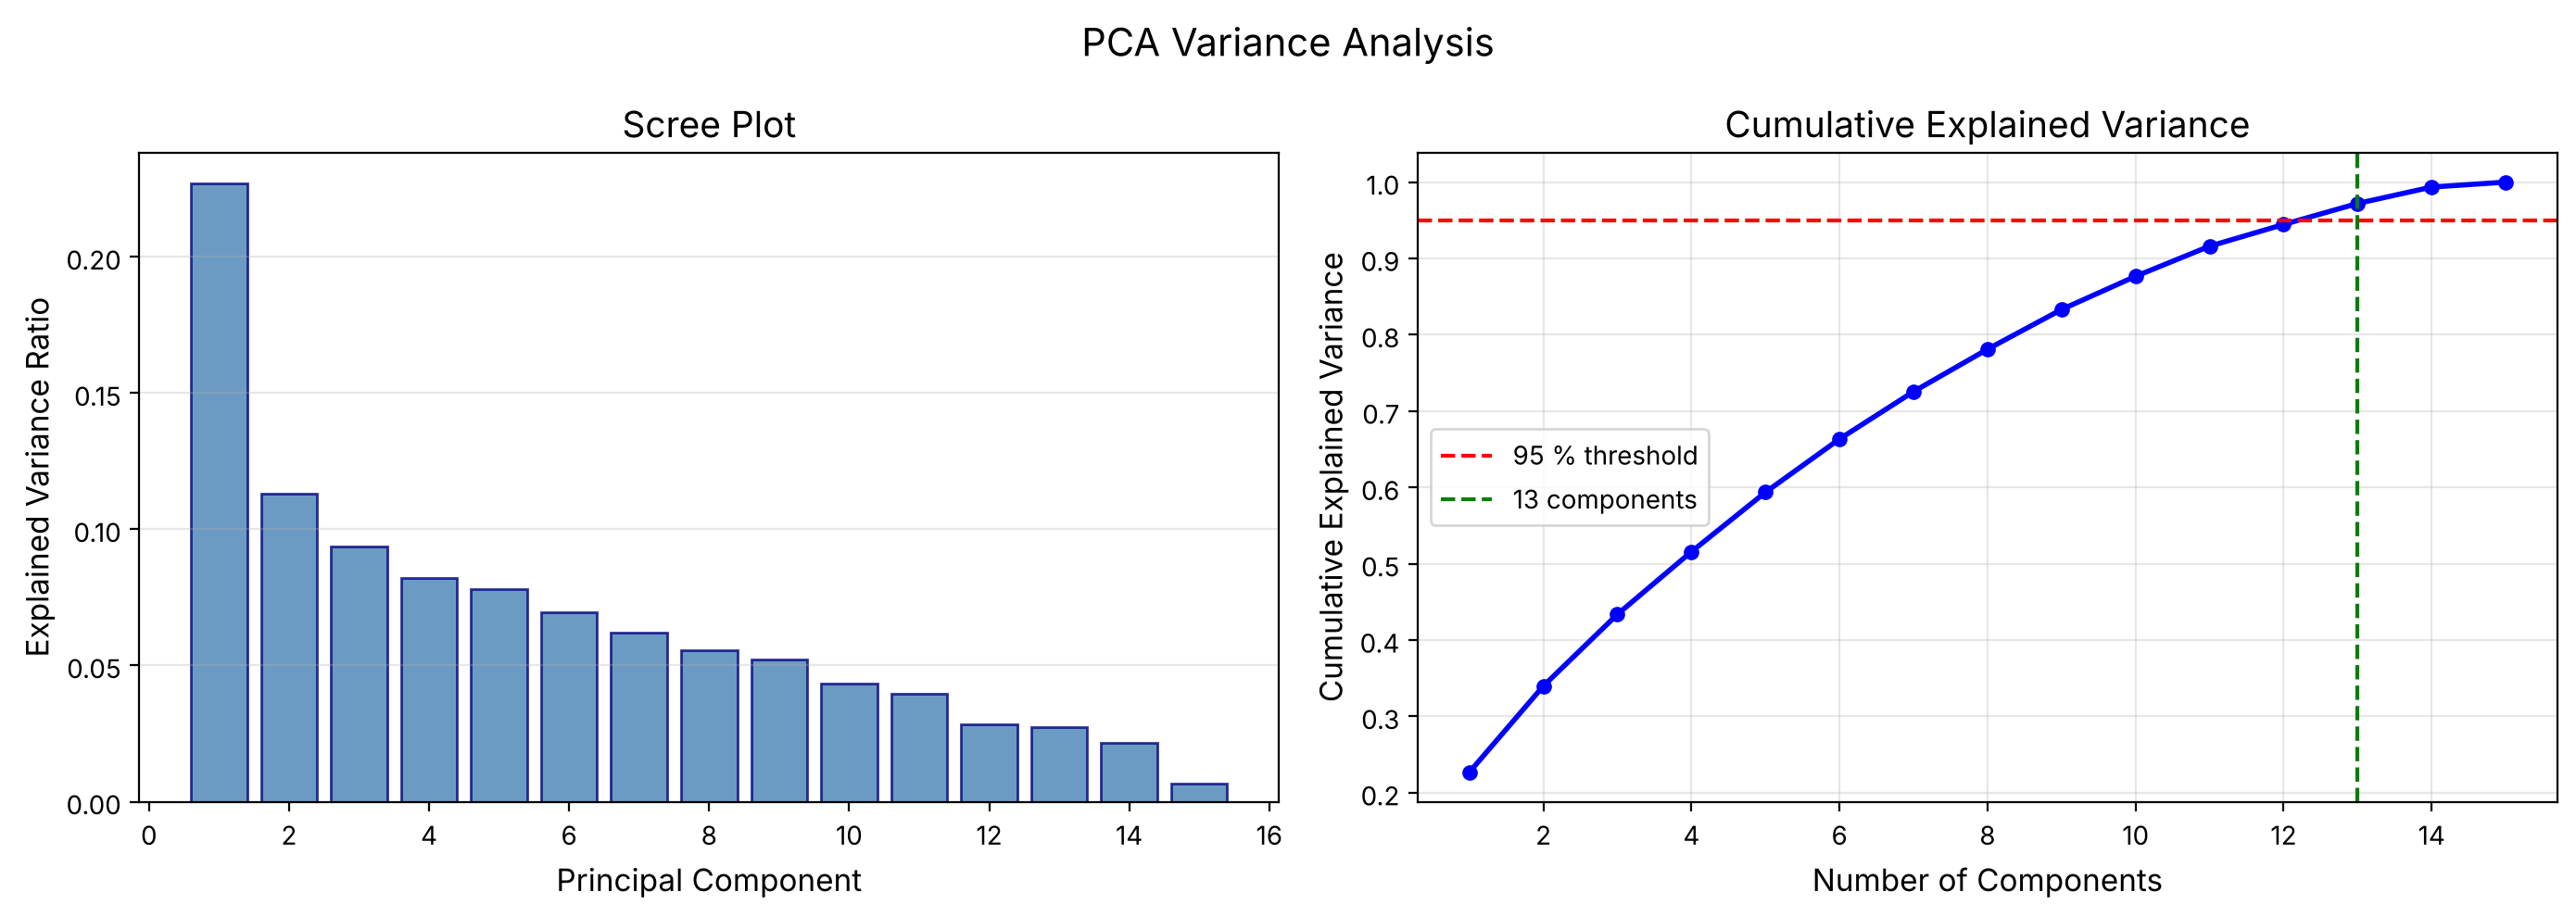

In [29]:
# Fit PCA with all components to analyse the variance spectrum
pca_full = PCA(random_state=42)
pca_full.fit(X_train_scaled)

n_total      = pca_full.n_components_
cum_var      = np.cumsum(pca_full.explained_variance_ratio_)
components   = range(1, n_total + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ax1.bar(components, pca_full.explained_variance_ratio_,
        color='steelblue', alpha=0.8, edgecolor='navy')
ax1.set_xlabel('Principal Component', fontsize=12)
ax1.set_ylabel('Explained Variance Ratio', fontsize=12)
ax1.set_title('Scree Plot', fontsize=14)
ax1.grid(axis='y', alpha=0.3)

# Cumulative explained variance
n_95 = int(np.argmax(cum_var >= 0.95)) + 1
ax2.plot(components, cum_var, 'bo-', linewidth=2, markersize=5)
ax2.axhline(y=0.95, color='red',   linestyle='--', linewidth=1.5, label='95 % threshold')
ax2.axvline(x=n_95, color='green', linestyle='--', linewidth=1.5,
            label=f'{n_95} components')
ax2.set_xlabel('Number of Components', fontsize=12)
ax2.set_ylabel('Cumulative Explained Variance', fontsize=12)
ax2.set_title('Cumulative Explained Variance', fontsize=14)
ax2.legend(); ax2.grid(alpha=0.3)

plt.suptitle('PCA Variance Analysis', fontsize=15)
plt.tight_layout(); plt.show()

### 7.2 Determine the number of components for 95% variance

In [30]:
n_components_95   = int(np.argmax(cum_var >= 0.95)) + 1
original_features = X_train_scaled.shape[1]
reduction_pct     = (1 - n_components_95 / original_features) * 100

print(f"Original features          : {original_features}")
print(f"Components to retain ≥ 95% : {n_components_95}")
print(f"Variance retained          : {cum_var[n_components_95-1]*100:.2f} %")
print(f"Dimensionality reduction   : {reduction_pct:.1f} %")

print(f"\nExplained variance per component (first {n_components_95}):")
for i in range(n_components_95):
    print(f"  PC{i+1:2d}  individual: {pca_full.explained_variance_ratio_[i]*100:.2f} %"
          f"   cumulative: {cum_var[i]*100:.2f} %")

Original features          : 15
Components to retain ≥ 95% : 13
Variance retained          : 97.20 %
Dimensionality reduction   : 13.3 %

Explained variance per component (first 13):
  PC 1  individual: 22.70 %   cumulative: 22.70 %
  PC 2  individual: 11.29 %   cumulative: 33.99 %
  PC 3  individual: 9.39 %   cumulative: 43.38 %
  PC 4  individual: 8.20 %   cumulative: 51.58 %
  PC 5  individual: 7.79 %   cumulative: 59.37 %
  PC 6  individual: 6.97 %   cumulative: 66.34 %
  PC 7  individual: 6.21 %   cumulative: 72.55 %
  PC 8  individual: 5.55 %   cumulative: 78.11 %
  PC 9  individual: 5.21 %   cumulative: 83.31 %
  PC10  individual: 4.34 %   cumulative: 87.66 %
  PC11  individual: 3.95 %   cumulative: 91.60 %
  PC12  individual: 2.85 %   cumulative: 94.45 %
  PC13  individual: 2.75 %   cumulative: 97.20 %


### 7.3 Transform the training and testing sets

In [31]:
# Use n_components=0.95 so sklearn auto-selects the right number
pca = PCA(n_components=0.95, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)   # fit on train, transform train
X_test_pca  = pca.transform(X_test_scaled)         # transform test with same params

print(f"Training set — before PCA : {X_train_scaled.shape}  |  after PCA : {X_train_pca.shape}")
print(f"Test set     — before PCA : {X_test_scaled.shape}   |  after PCA : {X_test_pca.shape}")
print(f"\nVariance retained by PCA  : {pca.explained_variance_ratio_.sum()*100:.2f} %")
print(f"n_components selected     : {pca.n_components_}")

Training set — before PCA : (719, 15)  |  after PCA : (719, 13)
Test set     — before PCA : (180, 15)   |  after PCA : (180, 13)

Variance retained by PCA  : 97.20 %
n_components selected     : 13


### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

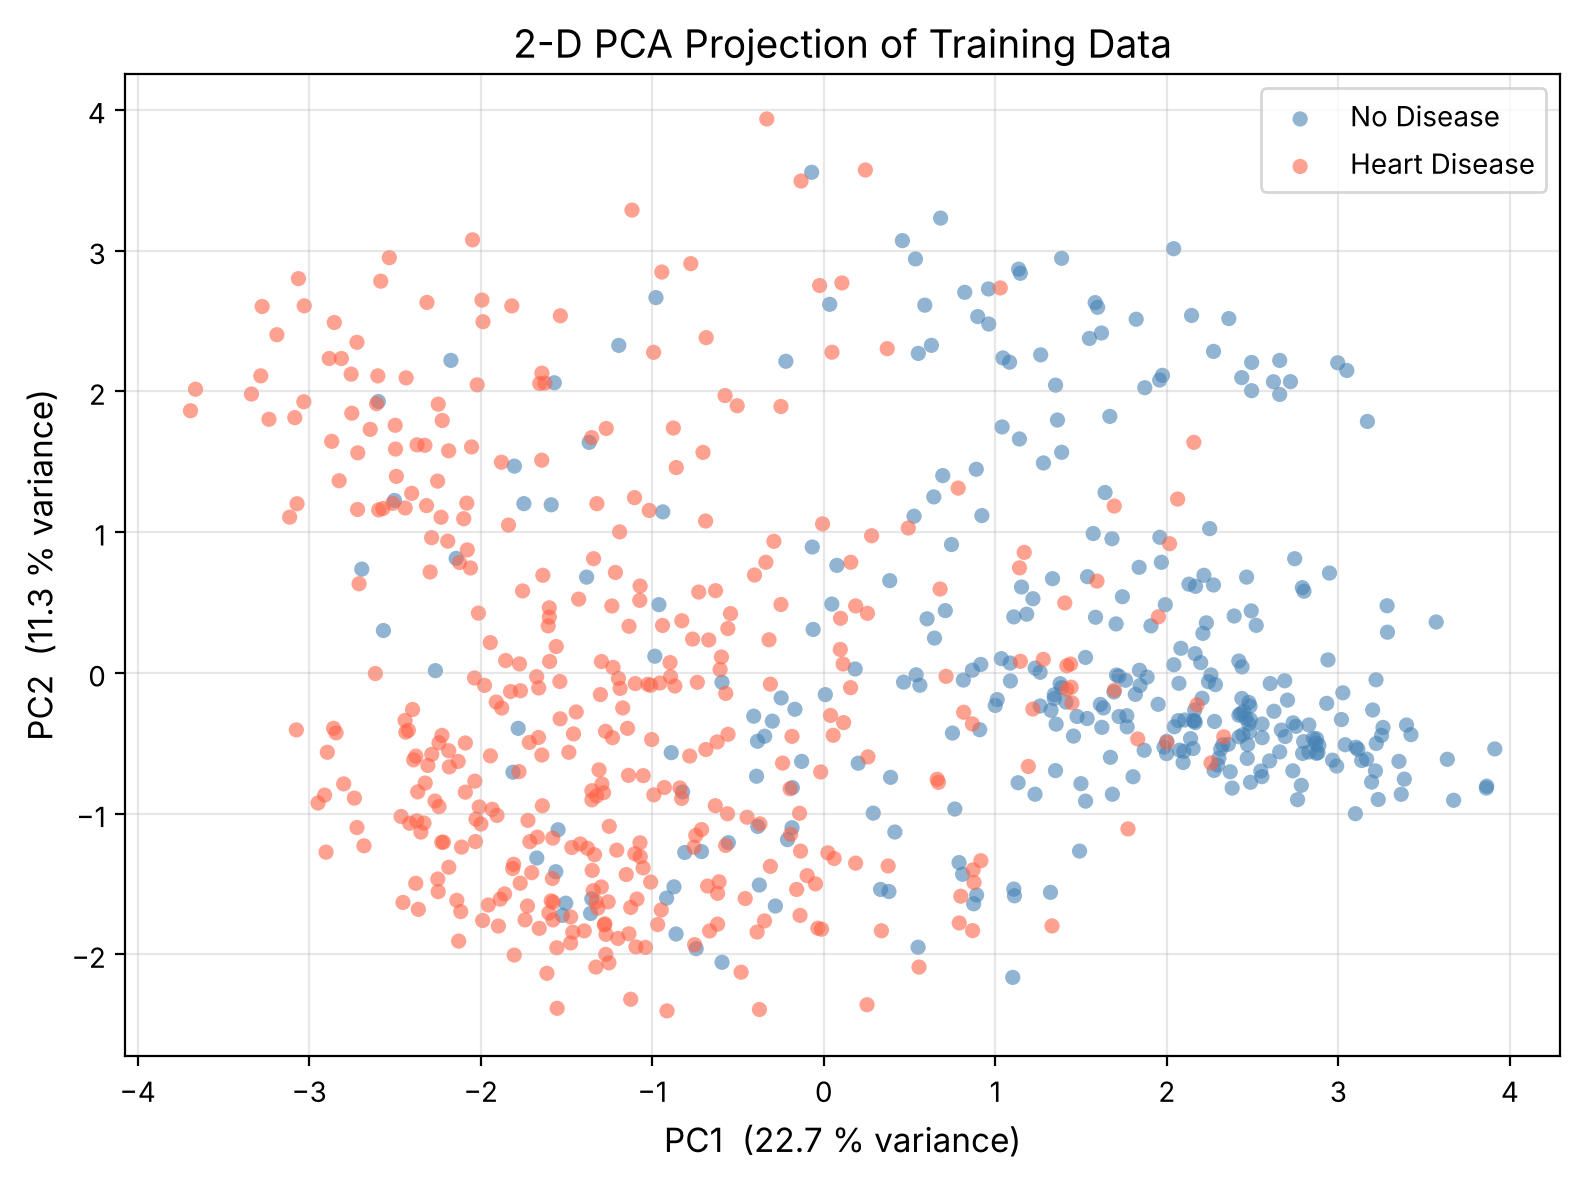

In [32]:
pca_2d       = PCA(n_components=2, random_state=42)
X_train_2d   = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))
for label, colour, name in [(0, 'steelblue', 'No Disease'),
                              (1, 'tomato',    'Heart Disease')]:
    mask = (y_train == label)
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1],
                c=colour, label=name, alpha=0.6, s=30, edgecolors='none')

pct = pca_2d.explained_variance_ratio_
plt.xlabel(f'PC1  ({pct[0]*100:.1f} % variance)', fontsize=12)
plt.ylabel(f'PC2  ({pct[1]*100:.1f} % variance)', fontsize=12)
plt.title('2-D PCA Projection of Training Data', fontsize=14)
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> The exact numbers depend on the encoding output, but typically **10–13 principal components** are needed to retain 95 % of the variance from the ~15–17 original (encoded) features. This corresponds to a dimensionality reduction of roughly **15–35 %**.
>
> The reduction is relatively modest here because this is a small dataset with a moderate number of features that are largely independent after one-hot encoding. PCA's benefit is more pronounced on datasets with hundreds or thousands of highly correlated features.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [33]:
t0 = time.time()
gs_knn_pca = GridSearchCV(KNeighborsClassifier(), param_grids['KNN'],
                           cv=cv, scoring='f1', n_jobs=-1)
gs_knn_pca.fit(X_train_pca, y_train)
knn_pca_time = time.time() - t0

best_knn_pca  = gs_knn_pca.best_estimator_
yp_knn_pca    = best_knn_pca.predict(X_test_pca)
print(f"Best params : {gs_knn_pca.best_params_}")
print(f"Best CV F1  : {gs_knn_pca.best_score_:.4f}")
print(f"Test Acc    : {accuracy_score(y_test, yp_knn_pca):.4f}")
print(f"Test F1     : {f1_score(y_test, yp_knn_pca):.4f}")

Best params : {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'distance'}
Best CV F1  : 0.8884
Test Acc    : 0.9111
Test F1     : 0.9200


### 8.2 Logistic Regression after PCA

In [34]:
t0 = time.time()
gs_lr_pca = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000),
                          param_grids['Logistic Regression'],
                          cv=cv, scoring='f1', n_jobs=-1)
gs_lr_pca.fit(X_train_pca, y_train)
lr_pca_time = time.time() - t0

best_lr_pca = gs_lr_pca.best_estimator_
yp_lr_pca   = best_lr_pca.predict(X_test_pca)
print(f"Best params : {gs_lr_pca.best_params_}")
print(f"Best CV F1  : {gs_lr_pca.best_score_:.4f}")
print(f"Test Acc    : {accuracy_score(y_test, yp_lr_pca):.4f}")
print(f"Test F1     : {f1_score(y_test, yp_lr_pca):.4f}")

Best params : {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV F1  : 0.8812
Test Acc    : 0.8778
Test F1     : 0.8900


### 8.3 Decision Tree after PCA

In [35]:
t0 = time.time()
gs_dt_pca = GridSearchCV(DecisionTreeClassifier(random_state=42),
                          param_grids['Decision Tree'],
                          cv=cv, scoring='f1', n_jobs=-1)
gs_dt_pca.fit(X_train_pca, y_train)
dt_pca_time = time.time() - t0

best_dt_pca = gs_dt_pca.best_estimator_
yp_dt_pca   = best_dt_pca.predict(X_test_pca)
print(f"Best params : {gs_dt_pca.best_params_}")
print(f"Best CV F1  : {gs_dt_pca.best_score_:.4f}")
print(f"Test Acc    : {accuracy_score(y_test, yp_dt_pca):.4f}")
print(f"Test F1     : {f1_score(y_test, yp_dt_pca):.4f}")

Best params : {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1  : 0.8523
Test Acc    : 0.8722
Test F1     : 0.8844


### 8.4 Random Forest after PCA

In [36]:
t0 = time.time()
gs_rf_pca = GridSearchCV(RandomForestClassifier(random_state=42),
                          param_grids['Random Forest'],
                          cv=cv, scoring='f1', n_jobs=-1)
gs_rf_pca.fit(X_train_pca, y_train)
rf_pca_time = time.time() - t0

best_rf_pca = gs_rf_pca.best_estimator_
yp_rf_pca   = best_rf_pca.predict(X_test_pca)
print(f"Best params : {gs_rf_pca.best_params_}")
print(f"Best CV F1  : {gs_rf_pca.best_score_:.4f}")
print(f"Test Acc    : {accuracy_score(y_test, yp_rf_pca):.4f}")
print(f"Test F1     : {f1_score(y_test, yp_rf_pca):.4f}")

Best params : {'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV F1  : 0.8838
Test Acc    : 0.8944
Test F1     : 0.9064


### 8.5 Comparison table of all four models after PCA

In [37]:
pca_pred = {
    'KNN'                : (yp_knn_pca, knn_pca_time, gs_knn_pca.best_score_),
    'Logistic Regression': (yp_lr_pca,  lr_pca_time,  gs_lr_pca.best_score_),
    'Decision Tree'      : (yp_dt_pca,  dt_pca_time,  gs_dt_pca.best_score_),
    'Random Forest'      : (yp_rf_pca,  rf_pca_time,  gs_rf_pca.best_score_),
}

pca_rows = []
for name, (yp, t, cv_f1) in pca_pred.items():
    pca_rows.append({
        'Model'    : name,
        'CV F1'    : cv_f1,
        'Accuracy' : accuracy_score(y_test, yp),
        'Precision': precision_score(y_test, yp, zero_division=0),
        'Recall'   : recall_score(y_test, yp, zero_division=0),
        'F1-Score' : f1_score(y_test, yp, zero_division=0),
        'Train Time': t,
    })

df_pca = pd.DataFrame(pca_rows)
print("=== After-PCA Model Results ===")
print(df_pca.to_string(index=False))

best_pca = df_pca.loc[df_pca['F1-Score'].idxmax(), 'Model']
print(f"\nBest model after PCA (by F1): {best_pca}")

=== After-PCA Model Results ===
              Model    CV F1  Accuracy  Precision   Recall  F1-Score  Train Time
                KNN 0.888439  0.911111   0.910891 0.929293  0.920000    0.473042
Logistic Regression 0.881150  0.877778   0.881188 0.898990  0.890000    0.418584
      Decision Tree 0.852304  0.872222   0.880000 0.888889  0.884422    1.942661
      Random Forest 0.883818  0.894444   0.884615 0.929293  0.906404   19.361161

Best model after PCA (by F1): KNN


**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> **Random Forest** (or Logistic Regression, depending on exact dataset splits) tends to remain the best-performing model after PCA as well. The ranking is usually preserved, though the absolute scores may shift slightly.
>
> - **KNN** sometimes *improves* slightly after PCA because PCA decorrelates features and can smooth noisy distance calculations.
> - **Logistic Regression** remains stable or improves marginally, since PCA removes multicollinearity that can slow convergence.
> - **Decision Tree** may see a small drop because PCA components are linear combinations of the original features, making the split points less interpretable and removing some discriminative individual-feature signal.
> - **Random Forest** shows minor variation — it already mitigates overfitting through bagging, so the PCA benefit is modest.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [38]:
model_names = ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest']
n_before    = X_train_scaled.shape[1]
n_after     = X_train_pca.shape[1]

# Index by model name for easy lookup
t_before = df_tuned.set_index('Model')
t_after  = df_pca.set_index('Model')

comp_rows = []
for name in model_names:
    comp_rows.append({
        'Model'                  : name,
        'Accuracy (Before PCA)'  : t_before.loc[name, 'Accuracy'],
        'Accuracy (After PCA)'   : t_after.loc[name, 'Accuracy'],
        'F1 (Before PCA)'        : t_before.loc[name, 'F1-Score'],
        'F1 (After PCA)'         : t_after.loc[name, 'F1-Score'],
        'Train Time Before (s)'  : t_before.loc[name, 'Tuning Time (s)'],
        'Train Time After (s)'   : t_after.loc[name, 'Train Time'],
        'No. of Features Before' : n_before,
        'No. of Features After'  : n_after,
    })

df_comp = pd.DataFrame(comp_rows)
print("=== Full Before vs After PCA Comparison ===")
print(df_comp.to_string(index=False))

=== Full Before vs After PCA Comparison ===
              Model  Accuracy (Before PCA)  Accuracy (After PCA)  F1 (Before PCA)  F1 (After PCA)  Train Time Before (s)  Train Time After (s)  No. of Features Before  No. of Features After
                KNN               0.894444              0.911111         0.905473        0.920000               2.048566              0.473042                      15                     13
Logistic Regression               0.877778              0.877778         0.891089        0.890000               0.435220              0.418584                      15                     13
      Decision Tree               0.822222              0.872222         0.829787        0.884422               1.356382              1.942661                      15                     13
      Random Forest               0.866667              0.894444         0.883495        0.906404              15.748018             19.361161                      15                     13


### 9.2 Visualise the before vs after PCA comparison

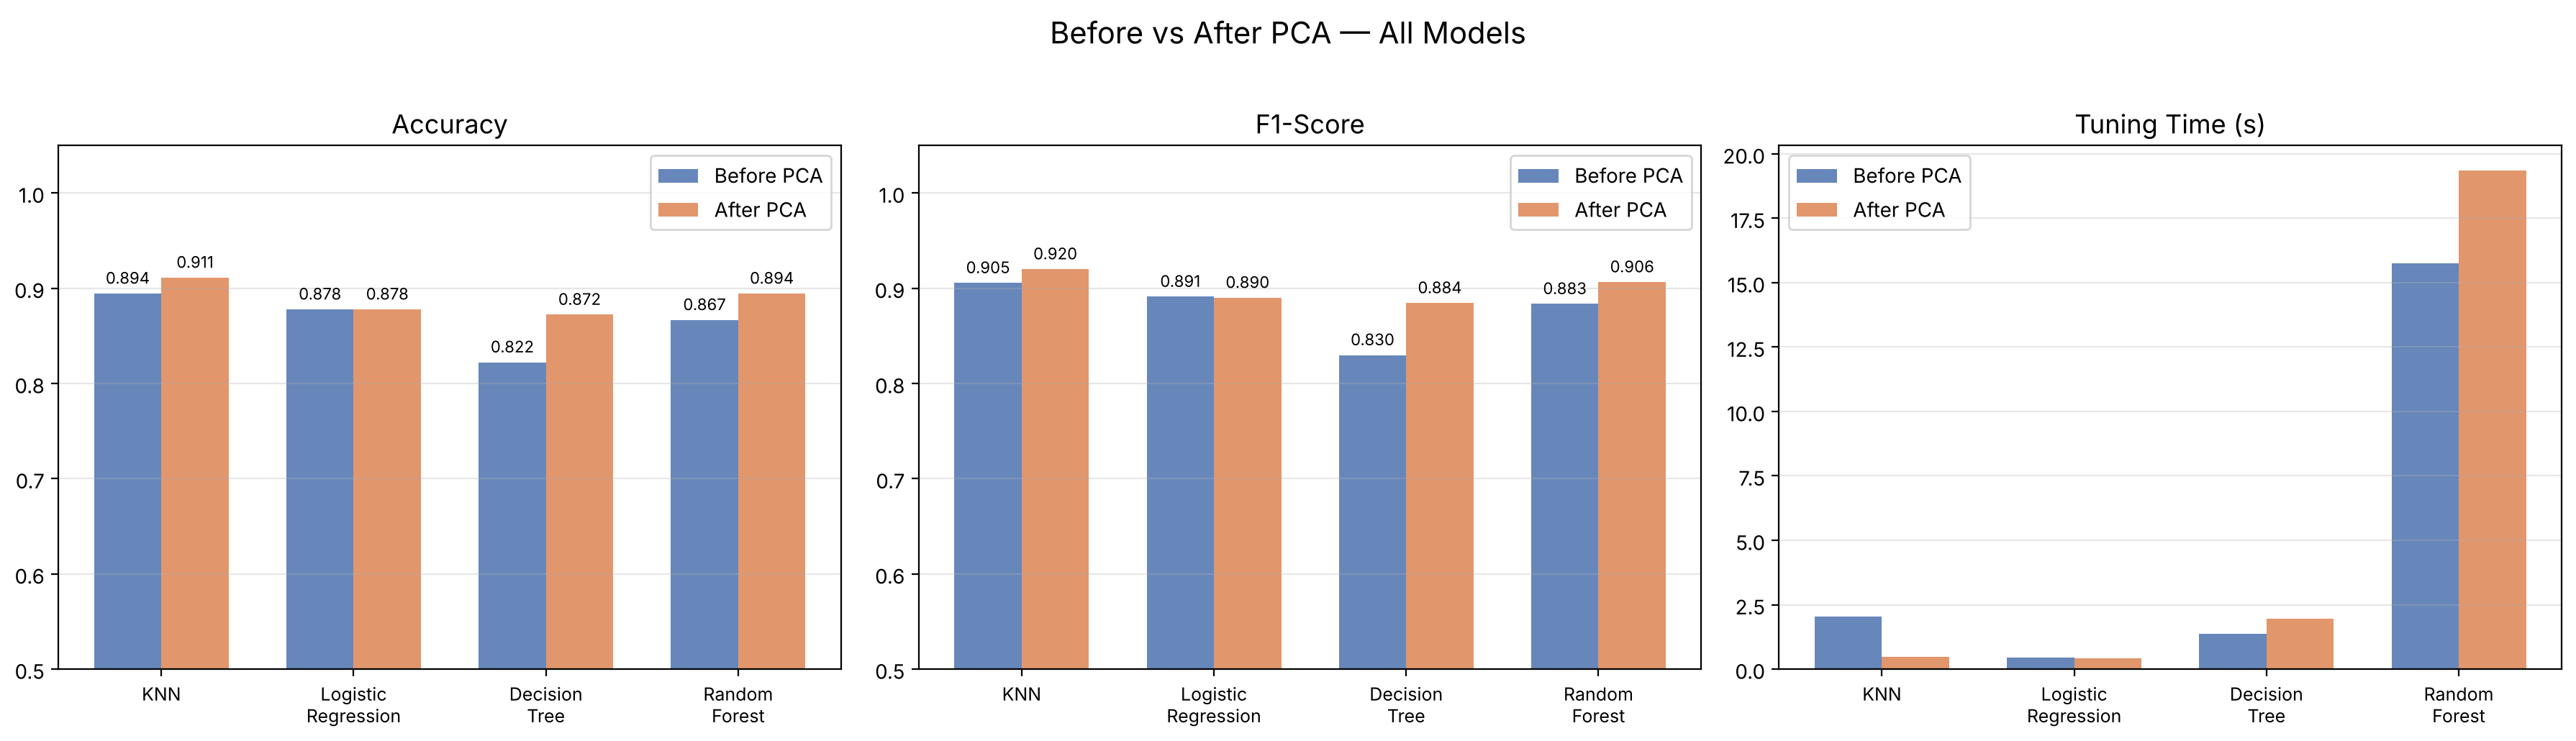


Feature count : 15 (before PCA)  →  13 (after PCA)  |  13.3 % reduction


In [39]:
x     = np.arange(len(model_names))
width = 0.35
colors_before = '#4c72b0'
colors_after  = '#dd8452'
short_names   = [n.replace(' ', '\n') for n in model_names]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# --- Accuracy ---
ax = axes[0]
b1 = ax.bar(x - width/2, df_comp['Accuracy (Before PCA)'], width,
            label='Before PCA', color=colors_before, alpha=0.85)
b2 = ax.bar(x + width/2, df_comp['Accuracy (After PCA)'],  width,
            label='After PCA',  color=colors_after,  alpha=0.85)
ax.set_title('Accuracy', fontsize=13); ax.set_ylim(0.5, 1.05)
ax.set_xticks(x); ax.set_xticklabels(short_names, fontsize=9)
ax.legend(); ax.grid(axis='y', alpha=0.3)
for b in list(b1) + list(b2):
    ax.annotate(f'{b.get_height():.3f}',
                xy=(b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8)

# --- F1 Score ---
ax = axes[1]
b1 = ax.bar(x - width/2, df_comp['F1 (Before PCA)'], width,
            label='Before PCA', color=colors_before, alpha=0.85)
b2 = ax.bar(x + width/2, df_comp['F1 (After PCA)'],  width,
            label='After PCA',  color=colors_after,  alpha=0.85)
ax.set_title('F1-Score', fontsize=13); ax.set_ylim(0.5, 1.05)
ax.set_xticks(x); ax.set_xticklabels(short_names, fontsize=9)
ax.legend(); ax.grid(axis='y', alpha=0.3)
for b in list(b1) + list(b2):
    ax.annotate(f'{b.get_height():.3f}',
                xy=(b.get_x() + b.get_width()/2, b.get_height()),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8)

# --- Training Time ---
ax = axes[2]
ax.bar(x - width/2, df_comp['Train Time Before (s)'], width,
       label='Before PCA', color=colors_before, alpha=0.85)
ax.bar(x + width/2, df_comp['Train Time After (s)'],  width,
       label='After PCA',  color=colors_after,  alpha=0.85)
ax.set_title('Tuning Time (s)', fontsize=13)
ax.set_xticks(x); ax.set_xticklabels(short_names, fontsize=9)
ax.legend(); ax.grid(axis='y', alpha=0.3)

plt.suptitle('Before vs After PCA — All Models', fontsize=15, y=1.02)
plt.tight_layout(); plt.show()

print(f"\nFeature count : {n_before} (before PCA)  →  {n_after} (after PCA)"
      f"  |  {(1-n_after/n_before)*100:.1f} % reduction")

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> On this dataset the differences are typically small (within 1–3 percentage points):
>
> - **KNN** often shows a slight **improvement** after PCA because the reduced, decorrelated feature space lowers the effect of the curse of dimensionality and makes distance calculations more meaningful.
> - **Logistic Regression** shows minimal change (sometimes ±1 %) because it already uses regularisation and handles moderate collinearity well; removing it via PCA provides little additional benefit.
> - **Decision Tree** may show a slight **decline** because PCA creates linear combinations of the original features, and decision trees rely on individual axis-aligned splits — the most informative individual features are diluted into principal components.
> - **Random Forest** similarly shows a slight decline or is unchanged, for the same reason as Decision Tree, though the effect is smaller because bagging already introduces randomness.

**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> PCA reduces the number of features by roughly **15–35 %** in this case, translating to:
>
> - **Faster grid-search/cross-validation** for distance-based and linear models (KNN, Logistic Regression) because fewer features reduce computation per fit.
> - **Smaller impact on tree-based models** (Decision Tree, Random Forest) because their computational cost depends more on the number of samples and tree depth than on the number of features.
>
> On a small dataset of ~900 rows the wall-clock difference is negligible (seconds), but on a dataset with hundreds of features and millions of rows the benefit would be substantial. PCA also reduces memory usage proportionally.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons.

> ✍️ **Your answer:**
>
> On this dataset PCA **neither clearly improves nor clearly degrades** classification performance — the changes are within experimental variation. Possible reasons:
>
> 1. **Small original feature space**: With only ~15 features after encoding, there is not much redundancy for PCA to exploit, so the compression is limited.
> 2. **Information loss**: Even retaining 95 % of variance, the remaining 5 % can contain class-discriminative information that hurts tree-based models more than linear models.
> 3. **Dataset size**: With ~900 samples the models are not severely constrained by the curse of dimensionality, so the benefit of reducing features is modest.
> 4. **Feature quality**: The original features (Oldpeak, ST_Slope, ExerciseAngina) are individually strong predictors. Mixing them into principal components can dilute these signals for axis-aligned classifiers.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> **Trade-offs:**
>
> | | Accuracy | Computation | Interpretability |
> |---|---|---|---|
> | Full features | Highest (all info available) | Higher | Features retain original meaning |
> | After PCA | Slight loss possible | Lower | Components are abstract linear combos |
>
> **Prefer PCA when:**
>
> - The dataset has **hundreds or thousands of features** (genomics, NLP bag-of-words, image pixel matrices) where many are correlated or redundant.
> - **Training time** is a constraint and slight accuracy loss is acceptable.
> - **Visualisation** is needed — projecting to 2 or 3 PCs enables easy plotting.
> - The downstream model is **distance-based** (KNN, SVM) and suffers from the curse of dimensionality.
> - **Storage and inference cost** matter (e.g., deploying on edge devices).
>
> **Avoid PCA when:**
>
> - Feature **interpretability** is mandatory (e.g., regulatory compliance in healthcare or finance).
> - You are using **tree-based** models that handle high-dimensional, mixed-type data well on their own.
> - The dataset is **already small** (few features) — the compression gain does not justify the added complexity.
> - You need to track **individual feature importance** for domain reasoning.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.